# Zijian Zhong — library panel OCR

## G1. Inputs and detection boxes
Run from the repository root. Set the five input paths below to the same upper panel at the same final size. Use a size-matched rectified original if the team changes resolution. Labels show the detection number in EasyOCR order and its prediction.

In [1]:
from pathlib import Path
import csv
import easyocr
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import display

reference = "University of Illinois"
folder = Path("rectification/library_demo/results")
inputs = {"original": folder / "rectified.png",
          **{f"P{i}": folder / f"P{i}.png" for i in range(1, 5)}}
output = Path("output/ocr")
output.mkdir(parents=True, exist_ok=True)
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(),
                        model_storage_directory=".easyocr_models",
                        user_network_directory=".easyocr_models/user_network")

In [2]:
def label_boxes(image, detections):
    canvas = Image.new("RGB", (image.width, image.height + 72), "white")
    canvas.paste(image, (0, 72))
    draw = ImageDraw.Draw(canvas)
    font = ImageFont.load_default(size=32)
    for number, (box, word, confidence) in enumerate(detections, 1):
        points = [(int(x), int(y) + 72) for x, y in box]
        draw.line(points + [points[0]], fill="orange", width=5)
        draw.text((min(x for x, y in points), 16), f"{number}: {word}", font=font, fill="black")
    canvas.thumbnail((1440, 600))
    return canvas

## G2. Score the single-line panel
Compare the full prediction in EasyOCR order and sorted by the left edge of each box. Keep every detection in both scores. The manual reference covers the printed words. Uppercase the text and collapse whitespace before counting character edits. P1/P2 stylize before rectification, P3/P4 after. P2 and P4 use edge loss.

In [3]:
def normalize(text):
    return " ".join(text.upper().split())

def character_errors(reference, prediction):
    ref, pred = normalize(reference), normalize(prediction)
    if not ref:
        raise ValueError("A manual transcription is required.")
    previous = list(range(len(pred) + 1))
    for i, expected in enumerate(ref, start=1):
        current = [i]
        for j, observed in enumerate(pred, start=1):
            current.append(min(previous[j] + 1, current[j - 1] + 1,
                               previous[j - 1] + (expected != observed)))
        previous = current
    edits = previous[-1]
    return edits, edits / len(ref)

assert character_errors("ROOM 210", "ROOM 21O") == (1, 0.125)
assert character_errors("Library", "LIBRARY") == (0, 0)

original | Reference: University of Illinois


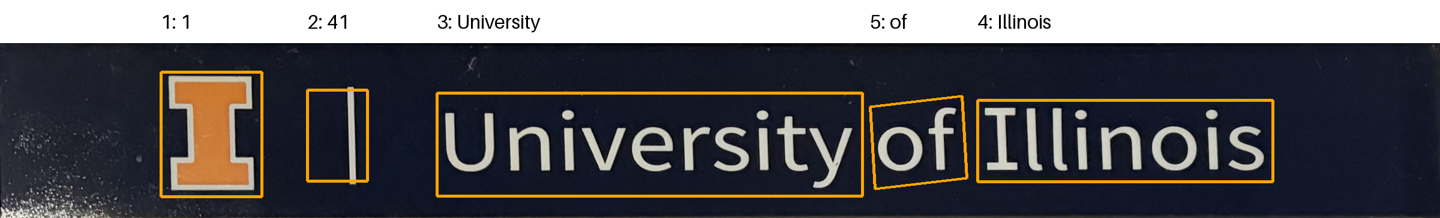

EasyOCR: '1 41 University Illinois of' | 11 edits | CER 50.0%
left-to-right: '1 41 University of Illinois' | 5 edits | CER 22.7%
P1: pending (rectification\library_demo\results\P1.png)
P2: pending (rectification\library_demo\results\P2.png)
P3: pending (rectification\library_demo\results\P3.png)
P4: pending (rectification\library_demo\results\P4.png)


In [4]:
with Image.open(inputs["original"]) as source:
    target_size = ImageOps.exif_transpose(source).size

rows = []
for variant, path in inputs.items():
    if not path.is_file():
        print(f"{variant}: pending ({path})")
        continue
    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
    if image.size != target_size:
        print(f"{variant}: skipped {image.size}; expected {target_size}")
        continue

    detections = reader.readtext(np.asarray(image), detail=1, decoder="greedy")
    annotated = label_boxes(image, detections)
    stem = "library_rectified" if variant == "original" else f"library_{variant}"
    annotated.save(output / f"{stem}_detections.png")
    print(f"{variant} | Reference: {reference}")
    display(annotated)
    ordered = sorted(detections, key=lambda item: min(point[0] for point in item[0]))
    for order, boxes in [("EasyOCR", detections), ("left-to-right", ordered)]:
        prediction = " ".join(word for box, word, confidence in boxes)
        edits, cer = character_errors(reference, prediction)
        print(f"{order}: {prediction!r} | {edits} edits | CER {cer:.1%}")
        rows.append([variant, str(path), order, reference, prediction, edits, cer])

with (output / "library_cer.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["variant", "path", "order", "reference", "prediction", "edits", "cer"])
    writer.writerows(rows)